<a href="https://colab.research.google.com/github/emilianomtz0189/credit-risk-scorecard/blob/main/notebooks/03_woe_iv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 · Agrupación de variables, WoE e IV

**Objetivo:** convertir cada variable en tramos de riesgo, medir qué tan predictiva es y elegir las que entrarán al scorecard.

Un **scorecard** es una tabla de puntos: cada característica del cliente (edad, uso de crédito, atrasos…) se divide en tramos y cada tramo da cierto número de puntos. La suma de puntos es la calificación del cliente, y a cada calificación le corresponde una **PD**. Este notebook construye los tramos; el notebook 04 les asigna los puntos.

## Conceptos

### 1. Agrupación de variables (*binning*)

Se hace en dos pasos:
- **Tramos finos (*fine classing*):** se corta cada variable en muchos tramos pequeños (hasta 20, por cuantiles).
- **Tramos gruesos (*coarse classing*):** se fusionan tramos vecinos hasta cumplir cuatro reglas:
  1. **Tamaño mínimo:** cada tramo tiene al menos 2 % de los clientes (unos 2,100 en entrenamiento). Un tramo con pocos clientes da estimaciones inestables. Ver la nota de la sección 1 sobre por qué se usa 2 % y no 5 %.
  2. **Tendencia monótona:** la tasa de malos siempre sube o siempre baja. Así el scorecard tiene lógica de negocio ("a mayor uso de crédito, más riesgo") y no premia ruido. La excepción son variables con una relación en U justificada por el negocio.
  3. **Máximo de 8 tramos:** un scorecard simple es más fácil de explicar y más estable en el tiempo.
  4. **Faltantes en su propio tramo**, como se decidió en la etapa 2.

### 2. WoE (*Weight of Evidence*, peso de la evidencia)

Para cada tramo:

$$\text{WoE} = \ln\left(\frac{\%\ \text{de los buenos que caen en el tramo}}{\%\ \text{de los malos que caen en el tramo}}\right)$$

| WoE | Significado |
|---|---|
| Positivo | El tramo concentra más buenos que malos: **menos riesgo** que el promedio. |
| Cero | Riesgo igual al promedio. |
| Negativo | El tramo concentra más malos que buenos: **más riesgo** que el promedio. |

**¿Por qué transformar a WoE?**
- **Captura relaciones no lineales:** en la etapa 2 vimos formas en U y saltos en un extremo; con WoE cada tramo recibe un valor según su riesgo real.
- **Maneja faltantes y extremos de forma natural:** cada uno es solo otro tramo.
- **Pone todas las variables en la misma escala** (logaritmo de momios, la misma que usa la regresión logística), lo que facilita convertir el modelo en puntos.

### 3. IV (*Information Value*, valor de la información)

Mide el poder predictivo de toda la variable:

$$\text{IV} = \sum_{\text{tramos}} (\%\ \text{buenos} - \%\ \text{malos}) \times \text{WoE}$$

| IV | Poder predictivo |
|---|---|
| Menos de 0.02 | Sin poder predictivo |
| 0.02 a 0.1 | Débil |
| 0.1 a 0.3 | Medio |
| 0.3 a 0.5 | Fuerte |
| Más de 0.5 | Muy fuerte: se revisa que no haya fuga de información |

## Entorno

In [1]:
import os
import sys
from pathlib import Path

USUARIO_GITHUB = "emilianomtz0189"
NOMBRE_REPO = "credit-risk-scorecard"
CARPETA_DRIVE = Path("/content/drive/MyDrive/credit-risk-scorecard")  # Donde está cs-training.csv

EN_COLAB = "google.colab" in sys.modules

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

    ruta_repo = Path("/content") / NOMBRE_REPO
    if not ruta_repo.exists():
        !git clone -q https://github.com/{USUARIO_GITHUB}/{NOMBRE_REPO}.git {ruta_repo}
    else:
        !git -C {ruta_repo} pull -q
    os.chdir(ruta_repo)
elif Path.cwd().name == "notebooks":
    os.chdir("..")

sys.path.insert(0, str(Path.cwd()))
print("Directorio de trabajo:", Path.cwd())

Mounted at /content/drive
Directorio de trabajo: /content/credit-risk-scorecard


In [2]:
!pip install -q -r requirements.txt

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.datos import copiar_datos_crudos
from src.eda import graficar_tasa_malos
from src.limpieza import obtener_datos_limpios
from src.woe import (
    NO_MONOTONICAS,
    VARIABLES_CANDIDATAS,
    AgrupadorWoE,
    graficar_iv,
    preparar_woe,
    seleccionar_variables,
)

config.fijar_semilla()
config.crear_carpetas()
pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.max_columns", 30)

In [4]:
# Datos limpios de la etapa 2 (se regeneran si es una sesión nueva de Colab)
copiar_datos_crudos(CARPETA_DRIVE)
train, test = obtener_datos_limpios()

Y = config.COLUMNA_OBJETIVO
TASA_GLOBAL = train[Y].mean()
print(f"Entrenamiento: {len(train):,} clientes | Prueba: {len(test):,} clientes")

Copiado cs-training.csv a data/raw/cs-training.csv
Entrenamiento: 105,000 clientes | Prueba: 45,000 clientes


## 1. Agrupación de todas las variables

El agrupador aprende los tramos **solo con entrenamiento**, como el limpiador de la etapa 2. `num_creditos_inmobiliarios` no se fuerza a tendencia monótona por su forma en U: tener 0 créditos inmobiliarios (sin patrimonio) o 4 o más (sobreendeudamiento) es más riesgoso que tener 1 o 2.

**Nota sobre el tamaño mínimo (2 % en lugar de 5 %).** Una regla común en la industria es exigir 5 % de clientes por tramo. En una primera corrida con 5 %, `atrasos_60_89` quedó con un solo tramo para todos los clientes con dato más el tramo "Faltante": el grupo con uno o más atrasos de 60 a 89 días tenía menos de 5 % de los clientes y se fusionó con el de cero atrasos. Su IV fue de solo 0.0375 y venía únicamente del tramo "Faltante". Así se perdía la información más valiosa de la variable: en la etapa 2, la tasa de malos pasaba de alrededor de 5 % con cero atrasos a más de 30 % con uno. Con 2 % (unos 2,100 clientes por tramo), los tramos siguen siendo estables y se conserva ese evento poco frecuente pero muy informativo.

In [5]:
agrupador = AgrupadorWoE(
    n_tramos_iniciales=20,     # Tramos finos
    pct_minimo=0.02,           # Mínimo 2 % de clientes por tramo
    max_tramos=8,              # Máximo de tramos por variable
    min_clientes_faltante=50,  # Faltantes con menos clientes reciben WoE = 0
    no_monotonicas=NO_MONOTONICAS,
).fit(train, VARIABLES_CANDIDATAS)

print("Variables sin tendencia monótona forzada:", NO_MONOTONICAS)

Variables sin tendencia monótona forzada: ['num_creditos_inmobiliarios']


## 2. Ejemplo paso a paso: edad

Antes de ver todas las variables, se revisa una tabla completa para entender cada columna:
- `clientes`, `malos`, `buenos`: conteos del tramo.
- `pct_clientes`: proporción de clientes en el tramo.
- `tasa_malos`: malos ÷ clientes del tramo.
- `dist_buenos`: qué parte de **todos los buenos** cae en el tramo.
- `dist_malos`: qué parte de **todos los malos** cae en el tramo.
- `woe` = ln(dist_buenos ÷ dist_malos).
- `iv` = (dist_buenos − dist_malos) × woe. La suma de esta columna es el IV de la variable.

In [6]:
tabla_edad = agrupador.tablas_["edad"]
tabla_edad

,clientes,malos,buenos,pct_clientes,tasa_malos,dist_buenos,dist_malos,woe,iv
tramo,,,,,,,,,
≤ 33,11943,1330,10613,0.1137,0.1114,0.1083,0.1895,-0.5594,0.0454
34–36,4728,471,4257,0.0450,0.0996,0.0434,0.0671,-0.4348,0.0103
37–41,10083,917,9166,0.0960,0.0909,0.0935,0.1307,-0.3342,0.0124
42–52,27407,2189,25218,0.2610,0.0799,0.2574,0.3119,-0.1922,0.0105
53–54,5053,351,4702,0.0481,0.0695,0.0480,0.0500,-0.0413,0.0001
55–58,9732,566,9166,0.0927,0.0582,0.0935,0.0806,0.1484,0.0019
59–63,12176,569,11607,0.1160,0.0467,0.1185,0.0811,0.3792,0.0142
64+,23878,625,23253,0.2274,0.0262,0.2373,0.0891,0.9801,0.1453


In [7]:
# El WoE del primer tramo, calculado a mano para comprobar la fórmula
fila = tabla_edad.iloc[0]
dist_buenos = fila["buenos"] / tabla_edad["buenos"].sum()
dist_malos = fila["malos"] / tabla_edad["malos"].sum()
woe = np.log(dist_buenos / dist_malos)

print(f"Tramo: {tabla_edad.index[0]}")
print(f"  % de todos los buenos en el tramo: {dist_buenos:.4f}")
print(f"  % de todos los malos en el tramo:  {dist_malos:.4f}")
print(f"  WoE = ln({dist_buenos:.4f} / {dist_malos:.4f}) = {woe:.4f}")
print(f"\nIV de edad (suma de la columna iv): {tabla_edad['iv'].sum():.4f}")

Tramo: ≤ 33
  % de todos los buenos en el tramo: 0.1083
  % de todos los malos en el tramo:  0.1895
  WoE = ln(0.1083 / 0.1895) = -0.5594

IV de edad (suma de la columna iv): 0.2401


## 3. IV de todas las variables

In [8]:
resumen_iv = agrupador.resumen_iv()
resumen_iv

,iv,tramos,poder_predictivo
variable,,,
uso_credito_revolvente,1.1254,9,Muy fuerte (revisar)
atrasos_90,0.8528,3,Muy fuerte (revisar)
atrasos_30_59,0.7395,5,Muy fuerte (revisar)
atrasos_60_89,0.5786,3,Muy fuerte (revisar)
edad,0.2401,8,Medio
num_creditos_abiertos,0.0772,5,Débil
razon_deuda,0.0770,9,Débil
ingreso_mensual,0.0746,9,Débil
num_creditos_inmobiliarios,0.0617,5,Débil


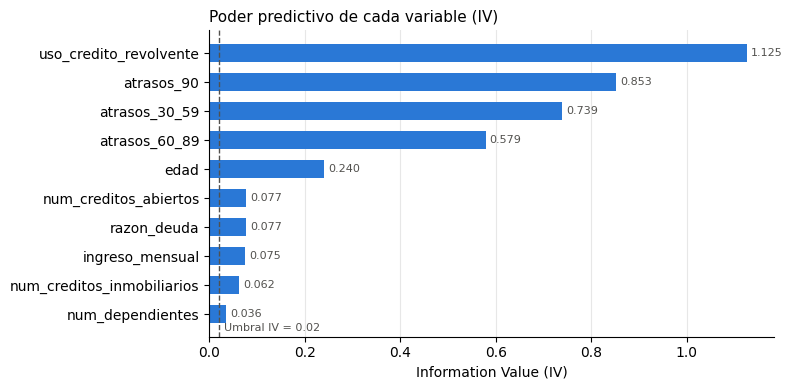

In [9]:
graficar_iv(resumen_iv)
plt.show()

## 4. Tramos finales por variable

Para cada variable: la tabla de tramos con su WoE y la tasa de malos por tramo. Lo que se revisa:
- Que la tendencia tenga sentido de negocio.
- Que ningún tramo sea demasiado pequeño.
- Cómo se comporta el tramo "Faltante".


uso_credito_revolvente  |  IV = 1.1254


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
≤ 0.27,62899,0.5990,1352,0.0215,1.1819,0.5147
0.27 – 0.35,5241,0.0499,242,0.0462,0.3917,0.0065
0.35 – 0.44,5242,0.0499,305,0.0582,0.1479,0.0010
0.44 – 0.56,5241,0.0499,401,0.0765,-0.1456,0.0011
0.56 – 0.69,5242,0.0499,530,0.1011,-0.4513,0.0124
0.69 – 0.85,5241,0.0499,745,0.1421,-0.8387,0.0506
0.85 – 1.00,13563,0.1292,2581,0.1903,-1.1882,0.3038
> 1.00,2162,0.0206,846,0.3913,-2.1945,0.2351
Faltante,169,0.0016,16,0.0947,-0.3785,0.0003


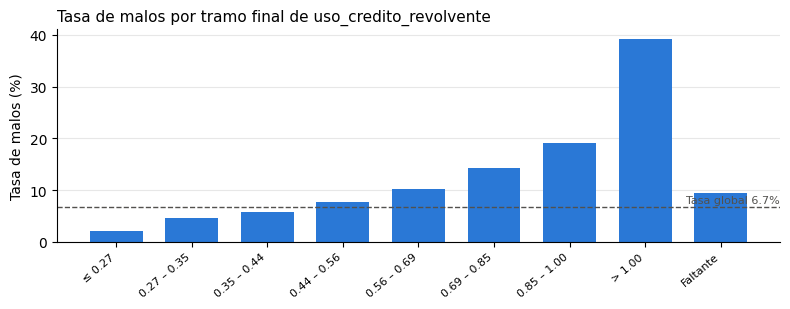


atrasos_90  |  IV = 0.8528


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
0,99103,0.9438,4558,0.0460,0.3959,0.1249
1+,5715,0.0544,2361,0.4131,-2.2852,0.6906
Faltante,182,0.0017,99,0.5440,-2.8126,0.0373


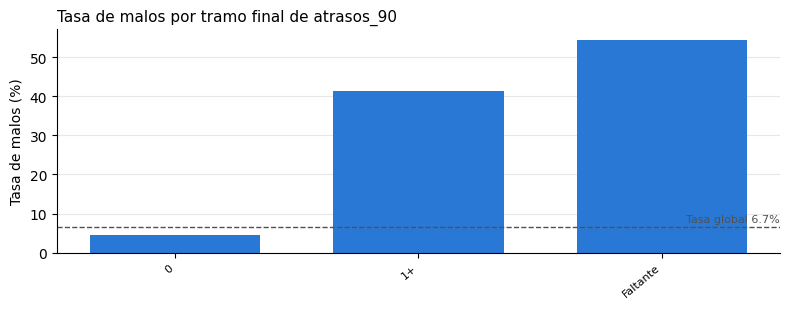


atrasos_30_59  |  IV = 0.7395


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
0,88178,0.8398,3560,0.0404,0.5321,0.1896
1,11252,0.1072,1660,0.1475,-0.8822,0.1223
2,3225,0.0307,866,0.2685,-1.6342,0.1623
3+,2163,0.0206,833,0.3851,-2.1684,0.2279
Faltante,182,0.0017,99,0.5440,-2.8126,0.0373


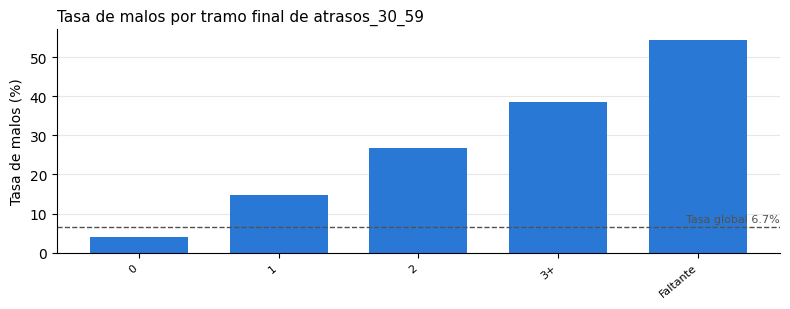


atrasos_60_89  |  IV = 0.5786


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
0,99662,0.9492,5072,0.0509,0.2895,0.0703
1+,5156,0.0491,1847,0.3582,-2.0532,0.4710
Faltante,182,0.0017,99,0.5440,-2.8126,0.0373


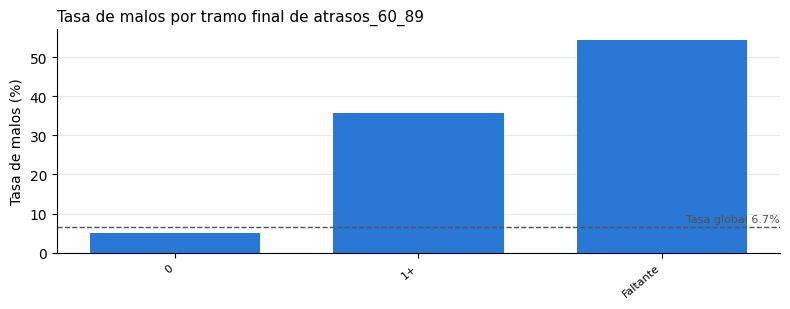


edad  |  IV = 0.2401


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
≤ 33,11943,0.1137,1330,0.1114,-0.5594,0.0454
34–36,4728,0.0450,471,0.0996,-0.4348,0.0103
37–41,10083,0.0960,917,0.0909,-0.3342,0.0124
42–52,27407,0.2610,2189,0.0799,-0.1922,0.0105
53–54,5053,0.0481,351,0.0695,-0.0413,0.0001
55–58,9732,0.0927,566,0.0582,0.1484,0.0019
59–63,12176,0.1160,569,0.0467,0.3792,0.0142
64+,23878,0.2274,625,0.0262,0.9801,0.1453


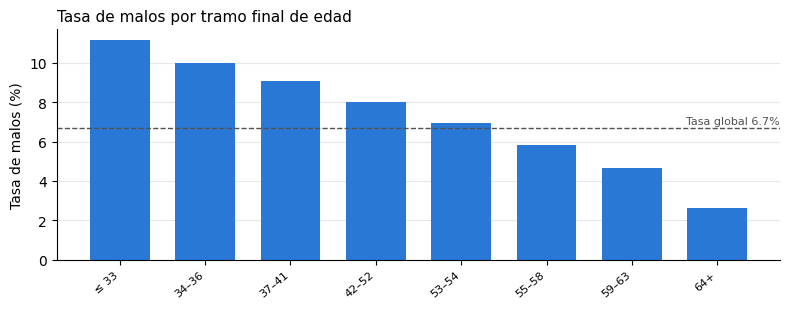


num_creditos_abiertos  |  IV = 0.0772


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
≤ 2,9042,0.0861,1174,0.1298,-0.7339,0.0638
3,6318,0.0602,480,0.0760,-0.1379,0.0012
4,8102,0.0772,524,0.0647,0.0352,0.0001
5,9014,0.0858,564,0.0626,0.0706,0.0004
6+,72524,0.6907,4276,0.0590,0.1338,0.0117


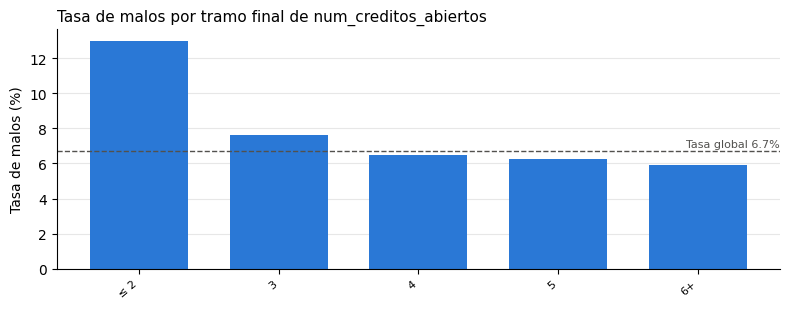


razon_deuda  |  IV = 0.0770


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
≤ 0.02,8315,0.0792,428,0.0515,0.2775,0.0054
0.02 – 0.36,41564,0.3958,2480,0.0597,0.1211,0.0055
0.36 – 0.43,8313,0.0792,542,0.0652,0.0266,0.0001
0.43 – 0.47,4156,0.0396,290,0.0698,-0.0462,0.0001
0.47 – 0.53,4157,0.0396,321,0.0772,-0.1556,0.0010
0.53 – 0.61,4156,0.0396,385,0.0926,-0.3545,0.0058
0.61 – 0.72,4158,0.0396,401,0.0964,-0.3989,0.0075
> 0.72,8312,0.0792,989,0.1190,-0.6342,0.0420
Faltante,21869,0.2083,1182,0.0540,0.2260,0.0097


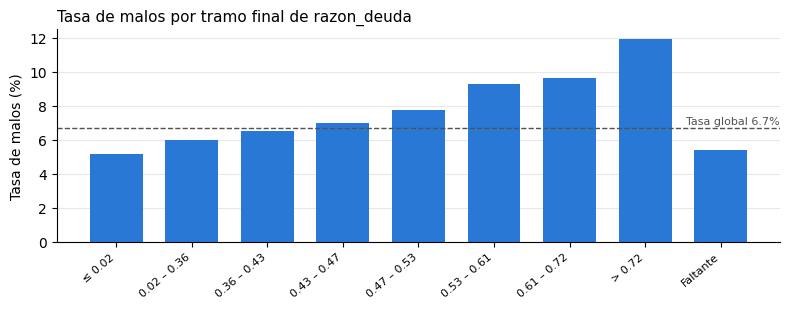


ingreso_mensual  |  IV = 0.0746


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
"≤ 3,400",21269,0.2026,1954,0.0919,-0.3453,0.0281
"3,401–3,800",4282,0.0408,368,0.0859,-0.2721,0.0034
"3,801–4,516",8160,0.0777,664,0.0814,-0.2125,0.0038
"4,517–5,382",8430,0.0803,627,0.0744,-0.1150,0.0011
"5,383–6,300",8555,0.0815,580,0.0678,-0.0153,0.0000
"6,301–7,500",8569,0.0816,501,0.0585,0.1427,0.0016
"7,501–10,075",12371,0.1178,641,0.0518,0.2706,0.0077
"10,076+",12641,0.1204,547,0.0433,0.4597,0.0209
Faltante,20723,0.1974,1136,0.0548,0.2110,0.0080


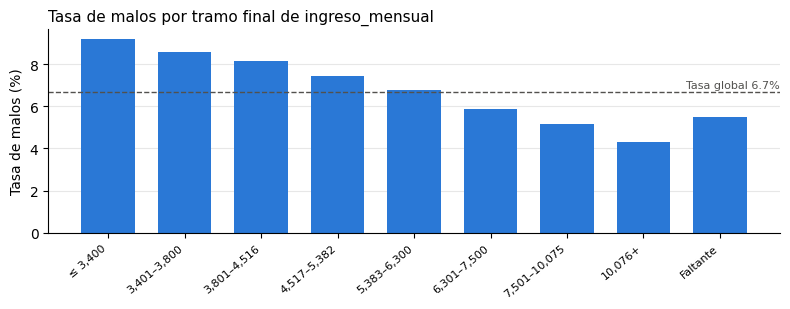


num_creditos_inmobiliarios  |  IV = 0.0617


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
0,39193,0.3733,3255,0.0831,-0.2347,0.0228
1,36731,0.3498,1919,0.0522,0.2619,0.0214
2,22106,0.2105,1240,0.0561,0.1867,0.0068
3,4426,0.0422,315,0.0712,-0.0675,0.0002
4+,2544,0.0242,289,0.1136,-0.5818,0.0106


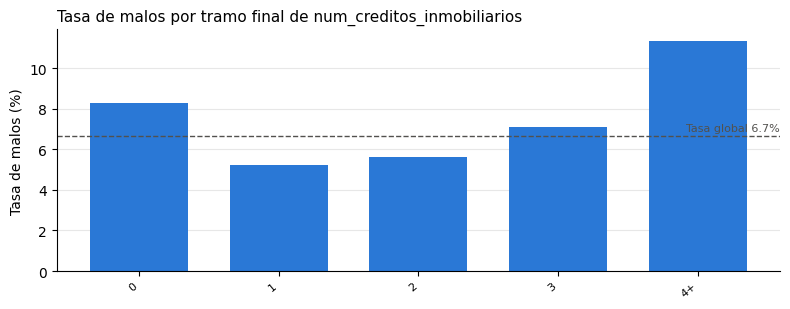


num_dependientes  |  IV = 0.0356


,clientes,pct_clientes,malos,tasa_malos,woe,iv
tramo,,,,,,
0,60782,0.5789,3580,0.0589,0.1349,0.0099
1,18498,0.1762,1366,0.0738,-0.1072,0.0021
2,13644,0.1299,1102,0.0808,-0.2043,0.0059
3,6647,0.0633,592,0.0891,-0.3112,0.0070
4+,2708,0.0258,265,0.0979,-0.4151,0.0053
Faltante,2721,0.0259,113,0.0415,0.5026,0.0053


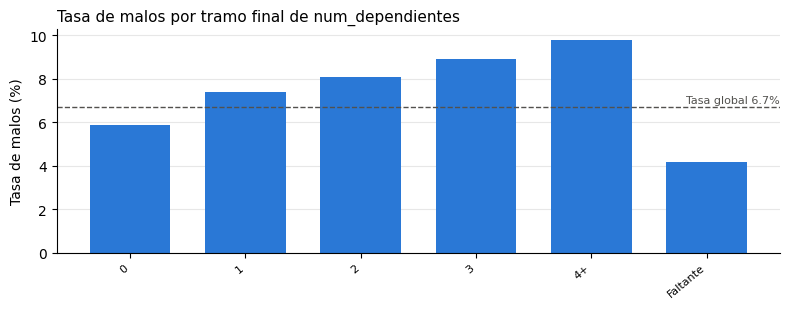

In [10]:
columnas = ["clientes", "pct_clientes", "malos", "tasa_malos", "woe", "iv"]

for variable in resumen_iv.index:
    tabla = agrupador.tablas_[variable]
    print(f"\n{variable}  |  IV = {tabla['iv'].sum():.4f}")
    display(tabla[columnas])
    graficar_tasa_malos(tabla, f"Tasa de malos por tramo final de {variable}", TASA_GLOBAL)
    plt.show()

## 5. Selección de variables

Dos filtros, en orden:
1. **IV mínimo de 0.02:** las variables sin poder predictivo solo agregan ruido.
2. **Redundancia:** si dos variables transformadas a WoE tienen correlación mayor a 0.7, dicen casi lo mismo y se conserva la de mayor IV. Esto evita la **multicolinealidad** en la regresión logística.

In [11]:
train_woe = agrupador.transform(train)
test_woe = agrupador.transform(test)   # Mismos tramos y WoE aprendidos en entrenamiento

seleccion, decisiones = seleccionar_variables(resumen_iv, train_woe)
decisiones

,iv,decision,motivo
variable,,,
uso_credito_revolvente,1.1254,Seleccionada,
atrasos_90,0.8528,Seleccionada,
atrasos_30_59,0.7395,Seleccionada,
atrasos_60_89,0.5786,Seleccionada,
edad,0.2401,Seleccionada,
num_creditos_abiertos,0.0772,Seleccionada,
razon_deuda,0.0770,Seleccionada,
ingreso_mensual,0.0746,Seleccionada,
num_creditos_inmobiliarios,0.0617,Seleccionada,


In [12]:
# Correlación entre las variables candidatas ya transformadas a WoE
candidatas = resumen_iv[resumen_iv["iv"] >= 0.02].index
train_woe[candidatas].corr().round(2)

,uso_credito_revolvente,atrasos_90,atrasos_30_59,atrasos_60_89,edad,num_creditos_abiertos,razon_deuda,ingreso_mensual,num_creditos_inmobiliarios,num_dependientes
uso_credito_revolvente,1.0000,0.2900,0.2800,0.2300,0.2500,0.2300,0.1500,0.1200,0.1000,0.0900
atrasos_90,0.2900,1.0000,0.2900,0.3300,0.1000,0.1700,-0.0000,0.0800,0.0800,0.0300
atrasos_30_59,0.2800,0.2900,1.0000,0.3200,0.1000,-0.0200,0.0900,0.0300,0.0100,0.0700
atrasos_60_89,0.2300,0.3300,0.3200,1.0000,0.0800,0.0600,0.0300,0.0500,0.0400,0.0300
edad,0.2500,0.1000,0.1000,0.0800,1.0000,0.0900,0.1100,0.1000,0.0200,0.2700
num_creditos_abiertos,0.2300,0.1700,-0.0200,0.0600,0.0900,1.0000,-0.2300,0.1500,0.3000,-0.1200
razon_deuda,0.1500,-0.0000,0.0900,0.0300,0.1100,-0.2300,1.0000,0.2700,-0.2000,0.1600
ingreso_mensual,0.1200,0.0800,0.0300,0.0500,0.1000,0.1500,0.2700,1.0000,0.1300,-0.0600
num_creditos_inmobiliarios,0.1000,0.0800,0.0100,0.0400,0.0200,0.3000,-0.2000,0.1300,1.0000,-0.1200
num_dependientes,0.0900,0.0300,0.0700,0.0300,0.2700,-0.1200,0.1600,-0.0600,-0.1200,1.0000


In [13]:
print(f"Variables seleccionadas ({len(seleccion)}):")
for variable in seleccion:
    print(f"  - {variable}  (IV = {resumen_iv.loc[variable, 'iv']:.4f})")

Variables seleccionadas (10):
  - uso_credito_revolvente  (IV = 1.1254)
  - atrasos_90  (IV = 0.8528)
  - atrasos_30_59  (IV = 0.7395)
  - atrasos_60_89  (IV = 0.5786)
  - edad  (IV = 0.2401)
  - num_creditos_abiertos  (IV = 0.0772)
  - razon_deuda  (IV = 0.0770)
  - ingreso_mensual  (IV = 0.0746)
  - num_creditos_inmobiliarios  (IV = 0.0617)
  - num_dependientes  (IV = 0.0356)


## 6. Guardar datos transformados

Se guardan entrenamiento y prueba con las variables seleccionadas en WoE. La función `preparar_woe()` de `src/woe.py` repite todo este proceso con los mismos parámetros, así el notebook 04 puede reconstruir los tramos en una sesión nueva. Aquí se comprueba que da exactamente el mismo resultado.

In [14]:
columnas_modelo = seleccion + [Y]
train_woe[columnas_modelo].to_csv(config.ARCHIVO_TRAIN_WOE)
test_woe[columnas_modelo].to_csv(config.ARCHIVO_TEST_WOE)

# Comprobación de reproducibilidad
_, seleccion_repetida, train_repetido, _ = preparar_woe()
assert seleccion_repetida == seleccion
assert np.allclose(train_repetido[seleccion], train_woe[seleccion])
print("Reproducible: preparar_woe() da los mismos tramos, WoE y variables.")
print("Guardado:", config.ARCHIVO_TRAIN_WOE.relative_to(config.RAIZ), "y",
      config.ARCHIVO_TEST_WOE.relative_to(config.RAIZ))

Reproducible: preparar_woe() da los mismos tramos, WoE y variables.
Guardado: data/processed/train_woe.csv y data/processed/test_woe.csv


## Hallazgos de la etapa

- **Poder predictivo (IV):** uso de crédito revolvente (1.1254), atrasos de 90+ días (0.8528), atrasos de 30–59 días (0.7395) y atrasos de 60–89 días (0.5786) son muy fuertes; edad (0.2401) es media; créditos abiertos (0.0772), razón de deuda (0.0770), ingreso (0.0746), créditos inmobiliarios (0.0617) y dependientes (0.0356) son débiles pero útiles.
- **Selección:** las 10 variables pasan el IV mínimo de 0.02 y ningún par de variables WoE supera la correlación de 0.7, así que todas entran al modelo.
- **Uso de crédito:** la tasa de malos sube en cada tramo. Los clientes que usan más del 100 % de su límite (2,162, el 2.06 %) tienen 39.13 % de malos (WoE de −2.19). El tramo "Faltante" (uso mayor a 10, 169 clientes) tiene 9.47 % de malos, mucho menos que los sobregirados reales.
- **Atrasos de 90+ días:** 94.38 % de los clientes no tiene ninguno y su tasa de malos es de 4.60 %; con uno o más, sube a 41.31 %; con códigos 96/98, a 54.40 %.
- **Ajuste del tamaño mínimo:** con 5 %, atrasos de 60–89 días quedaba sin separar a quienes tienen cero atrasos de quienes tienen uno o más (IV de 0.0375). Con 2 % se separan: 5.09 % de malos con cero atrasos frente a 35.82 % con uno o más, y el IV sube a 0.5786.
- **IV mayores a 0.5:** un IV tan alto puede indicar fuga de información. Aquí las variables describen el comportamiento pasado del cliente y el incumplimiento se mide después, así que su poder predictivo es legítimo: el historial de pago es el mejor predictor del pago futuro. La limitación es que el dataset no tiene fechas para comprobar ese orden, y el modelo dependerá mucho de estas variables; su estabilidad se revisa en la etapa 6.


## Resumen de la etapa

- Cada variable se agrupó en tramos con reglas de tamaño mínimo, tendencia monótona, máximo de tramos y faltantes como tramo propio, **aprendidas solo con entrenamiento**.
- Cada tramo recibió su WoE y cada variable su IV.
- Se eligieron las variables con IV de al menos 0.02 y sin redundancia.
- Se guardaron `train_woe.csv` y `test_woe.csv` en `data/processed/`.

**Siguiente paso:** notebook `04_scorecard.ipynb`, regresión logística sobre las variables WoE y conversión a puntos.